<a href="https://colab.research.google.com/github/bramhani007/192425319-MLA0204/blob/main/Practical_Problem_18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving iris (1).csv to iris (1).csv
IRIS DATASET:
    SepalLength  SepalWidth  PetalLength  PetalWidth     Species
0           5.1         3.5          1.4         0.2      Setosa
1           4.9         3.0          1.4         0.2      Setosa
2           4.7         3.2          1.3         0.2      Setosa
3           4.6         3.1          1.5         0.2      Setosa
4           5.0         3.6          1.4         0.2      Setosa
5           5.4         3.9          1.7         0.4      Setosa
6           4.6         3.4          1.4         0.3      Setosa
7           5.0         3.4          1.5         0.2      Setosa
8           4.4         2.9          1.4         0.2      Setosa
9           4.9         3.1          1.5         0.1      Setosa
10          7.0         3.2          4.7         1.4  Versicolor
11          6.4         3.2          4.5         1.5  Versicolor
12          6.9         3.1          4.9         1.5  Versicolor
13          5.5         2.3          4.0

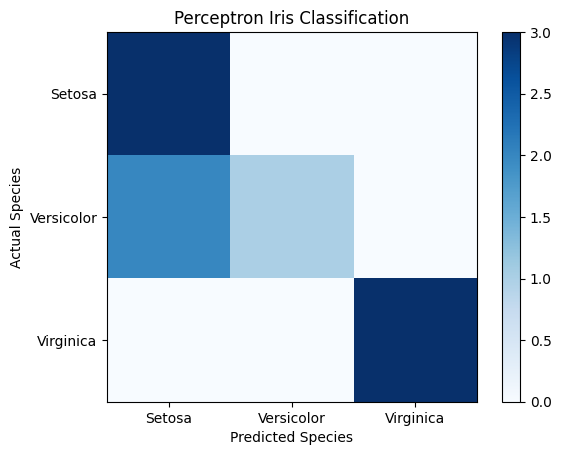

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import io
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Upload dataset
uploaded = files.upload()
filename = next(iter(uploaded))

data = pd.read_csv(io.BytesIO(uploaded[filename]))

print("IRIS DATASET:")
print(data)

# Input and output
X = data.drop("Species", axis=1)
y = data["Species"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Create Perceptron model
model = make_pipeline(
    StandardScaler(),
    Perceptron(
        max_iter=2000,
        eta0=0.1,
        random_state=42
    )
)

# Train model
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Display results
print("\nActual Species:")
print(y_test.values)

print("\nPredicted Species:")
print(y_pred)

# Accuracy
print("\nAccuracy:")
print(accuracy_score(y_test, y_pred) * 100, "%")

# Confusion Matrix
labels = ["Setosa", "Versicolor", "Virginica"]

cm = confusion_matrix(
    y_test, y_pred,
    labels=labels
)

print("\nConfusion Matrix:")
print(cm)

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    labels=labels,
    zero_division=0
))

# Plot confusion matrix
plt.imshow(cm, cmap="Blues")

plt.xticks(range(3), labels)
plt.yticks(range(3), labels)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.title("Perceptron Iris Classification")

plt.colorbar()
plt.show()